# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
print(plans.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
None


In [8]:
# inspección de users con .info()
print(users.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB
None


In [9]:
# inspección de usage con .info()
print(usage.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB
None


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("Cantidad de Valores Nulos Users")
print(users.isna().sum().sort_values())
print()
print("Proporción de Valores Nulos Users")
print(users.isna().mean().sort_values())

Cantidad de Valores Nulos Users
user_id          0
first_name       0
last_name        0
age              0
reg_date         0
plan             0
city           469
churn_date    3534
dtype: int64

Proporción de Valores Nulos Users
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
reg_date      0.00000
plan          0.00000
city          0.11725
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("Cantidad de Valores Nulos Usage")
print(usage.isna().sum().sort_values())
print()
print("Proporción de Valores Nulos Usage")
print(usage.isna().mean().sort_values())

Cantidad de Valores Nulos Usage
id              0
user_id         0
type            0
date           50
length      17896
duration    22076
dtype: int64

Proporción de Valores Nulos Usage
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
length      0.44740
duration    0.55190
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

  Para "users", tanto city como churn_date tienen una proporción del 11.72% y el 88.35% respectivamente, mientras que para usage las colunas con valores faltantes son date, length y duration con una proporción del 0.1%, 44.74% y 55.19% respectivamente.
  
- Indica qué harías: ¿imputar, eliminar, ignorar?

  Para la columna "date" intentaría convertir los valores y recuperarlos. En caso de no poder, eliminar.

  Tanto "length" como "duration" están relacionados con "type". No los intentaría imputar, ya que el "length" se usaría para mensajes de texto, mientras que el "duration" se usaría para llamadas.

  Para la columna "churn_date", el que haya valores nulos tiene sentido ya que representan personas que no han cancelado sus planes. Eliminaría los nulos.

  Para la columna "city", intentaría normalizar valores y recuperar los datos. En caso de no poder, ignorarlos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users_num = users[["user_id", "age"]]
users_num.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [13]:
users_num.median()

user_id    11999.5
age           47.0
dtype: float64

- La columna `user_id` es el valor para identificar al cliente, no es necesario profundizar en una informe estadístico.
- La columna `age` nos muestra una distribución Left-skewed, la cual se ve afectada por valores no erróneos como -999.

In [14]:
# explorar columnas numéricas de usage
usage_num = usage[["id", "user_id", "duration", "length"]]
usage_num.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [15]:
usage_num.median()

id          20000.5
user_id     12013.0
duration        3.5
length         50.0
dtype: float64

- Las columnas `id` y `user_id` son identificadores para cada llamada/texto y el usuario respectivamente. No es necesario un análisis estadístico.
- La columa `length` muestra un comportamiento similar tanto en su media como mediana, mientras que en `duration` la mediana es significativemente menor a la media, lo que puede deberse por la cantidad de "0" que se ven reflejados en esta columna cuando son textos

In [16]:
# explorar columnas categóricas de users
users_categ = users[['city', 'plan']]
users_categ.describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


In [17]:
users["city"].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

In [18]:
for col in ["city", "plan"]:
    print(f"\nValores únicos de {col}:")
    print(users_categ[col].unique())


Valores únicos de city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Valores únicos de plan:
['Basico' 'Premium']


- La columna `city` tiene 7 valores distintos, siendo Bogotá el más repetido.
- La columna `plan` tiene 2 valores distintos, siendo el Básico el más frecuente.

In [19]:
# explorar columna categórica de usage
usage[['type']].describe()

,type
count,40000
unique,2
top,text
freq,22092


- La columna `type` tiene 2 valores diferentes. Esta marca la diferencia en cuando será nulo el valor de `length` y `duration`.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

  En `age` vemos que el valor mínimo es -999.

  Vemos que para `city` no solo tenemos nan, sino que adicionalmente está "?".
  
- ¿Qué acción tomarías?

  Imputar la mediana en age y convertir el "?" en nan.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [20]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [21]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [24]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.sort_values().unique()

array([2022, 2023, 2024, 2026])

En `reg_date`, hay información errónea, ya que algunas columnas toman en sus valores el año 2026 a pesar de que la información registrada debería ser solo hasta 2024.

In [25]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.sort_values().unique()

array([2024.,   nan])

En `date`, vemos que hay valores nan.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

  En `reg_date` hay valores futuros como el 2026, mientras que en `date` aparecen nan.
  
- ¿Qué harías con ellas?

  Para `reg_date`, intentar corregirlo de ser posible, si no, volver nan.

  Para `date`, dejar el nan.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [26]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [27]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [28]:
# Marcar fechas futuras como NA para reg_date
mask = users['reg_date'].dt.year==2026
users.loc[mask, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.sort_values().unique()

array([2022., 2023., 2024.,   nan])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [29]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [30]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Podemos confirmar que ambas columnas dependen de la columna `type` para definir si se añadirá información a una u otra.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:
   
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [31]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    total_mensajes = ("is_text", "sum"),
    total_llamadas = ("is_call", "sum"),
    minutos_totales_llamada = ("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,total_mensajes,total_llamadas,minutos_totales_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [32]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'total_mensajes':'cant_mensajes',
                                      'total_llamadas': 'cant_llamadas',
                                     'minutos_totales_llamada': 'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [34]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [35]:
user_profile.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3999 entries, 0 to 3998
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               3999 non-null   int64         
 1   first_name            3999 non-null   object        
 2   last_name             3999 non-null   object        
 3   age                   3999 non-null   float64       
 4   city                  3434 non-null   object        
 5   reg_date              3959 non-null   datetime64[ns]
 6   plan                  3999 non-null   object        
 7   churn_date            466 non-null    object        
 8   cant_mensajes         3999 non-null   int64         
 9   cant_llamadas         3999 non-null   int64         
 10  cant_minutos_llamada  3999 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(5)
memory usage: 374.9+ KB


In [36]:
# Resumen estadístico de las columnas numéricas
col_numericas = user_profile[['user_id', 'age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']]
col_numericas.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,48.124531,5.524381,4.478120,23.317054
std,1154.898108,17.692032,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.500000,33.000000,4.000000,3.000000,11.120000
50%,12000.000000,47.000000,5.000000,4.000000,19.780000
75%,12999.500000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [37]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

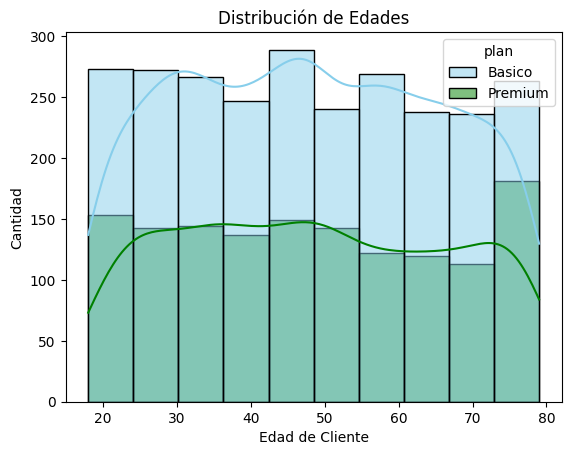

In [38]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,
             x = 'age', bins=10,
             palette=['skyblue', 'green'],
             kde=True,
             hue='plan'
)
plt.title("Distribución de Edades")
plt.ylabel("Cantidad")
plt.xlabel("Edad de Cliente")
plt.show()

💡Insights: Vemos distribuciones que parecen ser similares dependiendo de la edad, resaltando que los mayores de 70 años tienen mayor interés por un plan premium.
- Distribución ni simétrica ni sesgada. Tiene un segmento levemente dominante entre 40-50.

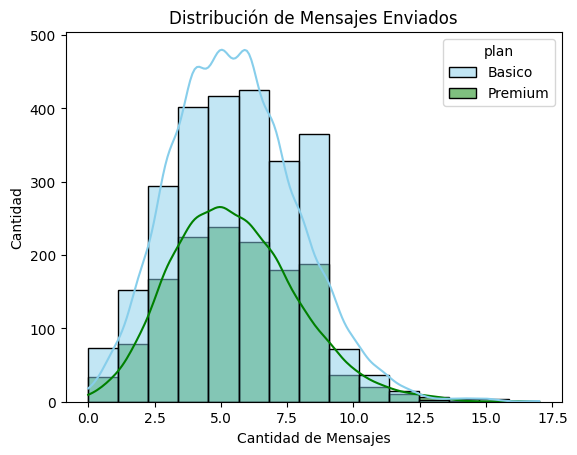

In [39]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile,
             x = 'cant_mensajes', bins=15,
             palette=['skyblue', 'green'],
             kde=True,
             hue='plan'
)
plt.title("Distribución de Mensajes Enviados")
plt.ylabel("Cantidad")
plt.xlabel("Cantidad de Mensajes")
plt.show()

💡Insights: Aunque leve, se puede apreciar una predominancia del plan premium a través de toda la gráfica.
- Distribución levemente sesgada a la derecha.

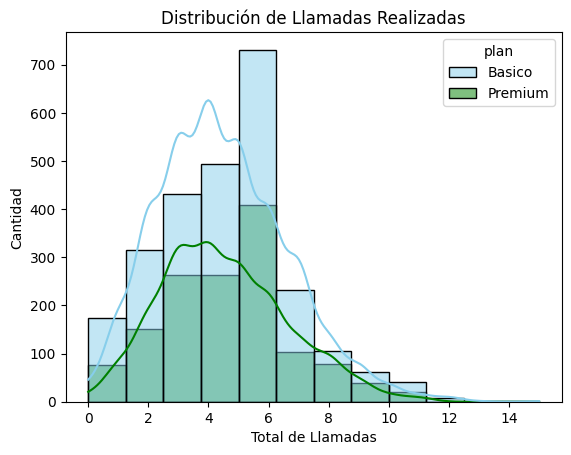

In [40]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,
             x = 'cant_llamadas', bins=12,
             palette=['skyblue', 'green'],
             kde=True,
             hue='plan'
)
plt.title("Distribución de Llamadas Realizadas")
plt.ylabel("Cantidad")
plt.xlabel("Total de Llamadas")
plt.show()

💡Insights: Al comparar con los mensajes de texto, podemos ver una predominancia aún mayor del plan premium en la cantidad de llamadas, remarcando que a partir de las 8 llamadas totales, cada barra se ve mayoritariamente verde.
- Distribución sesgada a la derecha con un claro segmento dominante sobre 6 llamadas totales.

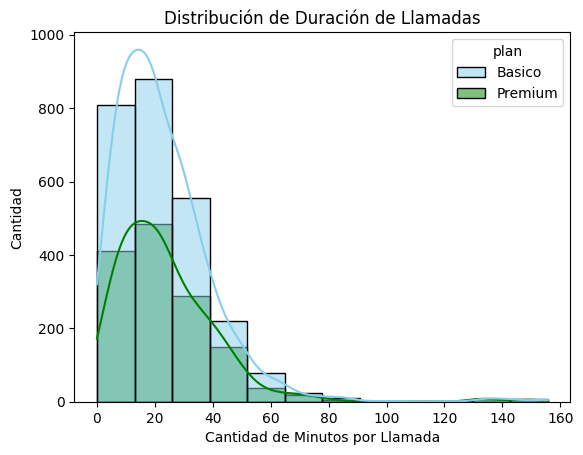

In [41]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,
             x = 'cant_minutos_llamada', bins=12,
             palette=['skyblue', 'green'],
             kde=True,
             hue='plan'
)
plt.title("Distribución de Duración de Llamadas")
plt.ylabel("Cantidad")
plt.xlabel("Cantidad de Minutos por Llamada")
plt.show()

💡Insights: La mayoría de los minutos por llamada se concentran de 0-40. Vemos algunos valores sobre los 140 minutos que requieren ser estudiados con mayor detenimiento. 

Clara distribución sesgada a la derecha.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

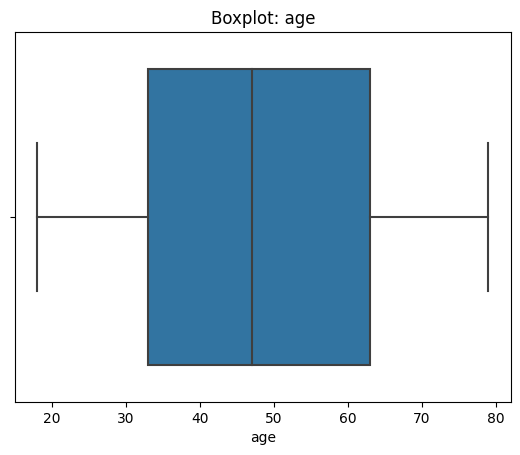

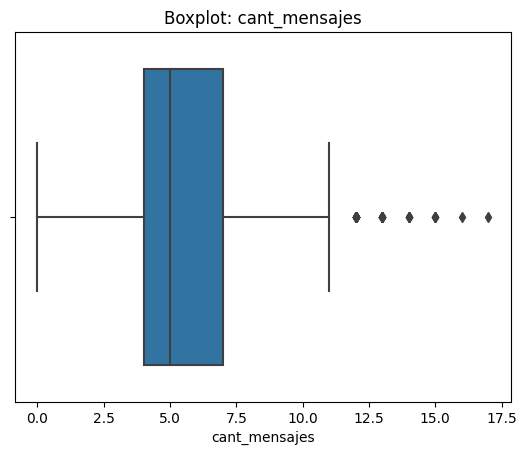

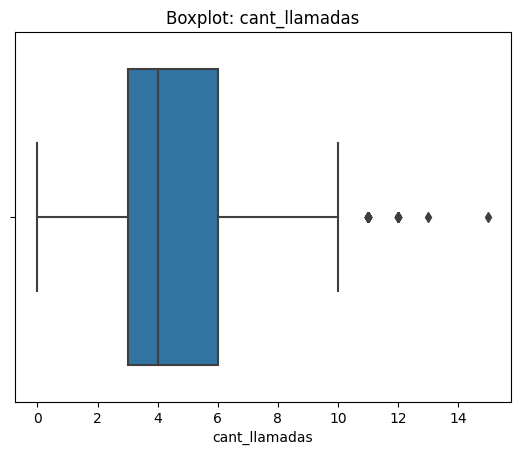

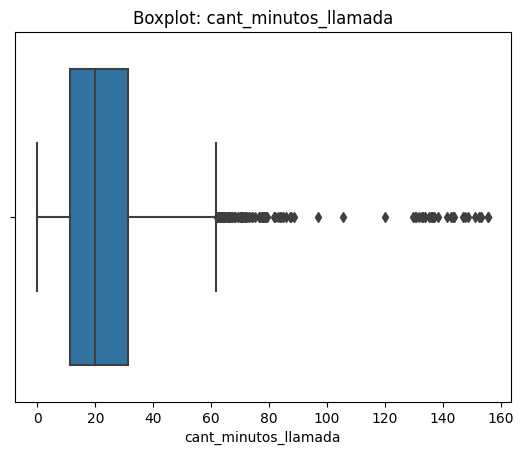

In [42]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers
- cant_mensajes: Vemos outliers por encima del rango superior, entre 12-17.5.
- cant_llamadas: Se presentan outliers por encima de 10.
- cant_minutos_llamada: Cantidad representativa de outliers por encima de 60 y llegando hasta 160.

In [43]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    print(f'Q1_{col}: ', Q1,"\n"
         f'Q3_{col}: ', Q3,"\n"
          f'IQR_{col}: ', IQR
         )

Q1_cant_mensajes:  4.0 
Q3_cant_mensajes:  7.0 
IQR_cant_mensajes:  3.0
Q1_cant_llamadas:  3.0 
Q3_cant_llamadas:  6.0 
IQR_cant_llamadas:  3.0
Q1_cant_minutos_llamada:  11.12 
Q3_cant_minutos_llamada:  31.415 
IQR_cant_minutos_llamada:  20.295


In [44]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? A pesar de que estadísticamente son valores atípicos, no son necesariamente incorrectos. Mantener
- cant_llamadas: mantener o no outliers, porqué? Al igual que con mensajes, a pesar de que matematicamente están fuera de los rangos, aún pueden ser valores reales. Mantener.
- cant_minutos_llamada: mantener o no outliers, porqué? Son considerablemente superiores al límite superior. Aun así, no podemos concluir que sea un error únicamente por su magnitud. Mantener.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [45]:
# Crear columna grupo_uso
def uso(row):

    use_texts = row['cant_mensajes']
    use_calls = row['cant_llamadas']

    if use_texts < 5 and use_calls < 5:
        return "Bajo uso"
    elif use_texts < 10 and use_calls < 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile['grupo_uso'] = user_profile.apply(uso, axis=1)

In [46]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [47]:
# Crear columna grupo_edad
def edades(row):

    edad = row['age']

    if edad < 30:
        return "Joven"
    elif edad < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad'] = user_profile.apply(edades, axis=1)

In [48]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

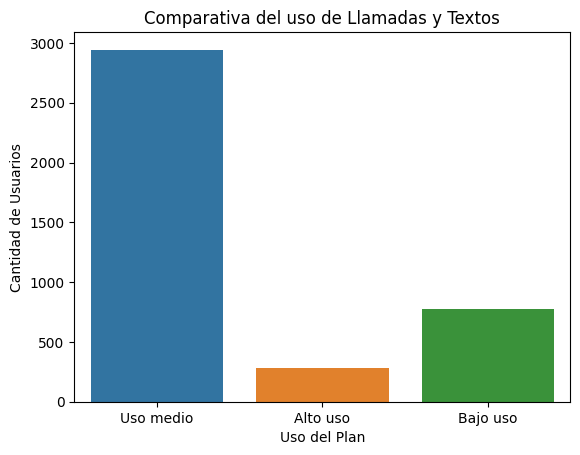

In [49]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title("Comparativa del uso de Llamadas y Textos")
plt.ylabel("Cantidad de Usuarios")
plt.xlabel("Uso del Plan")
plt.show()

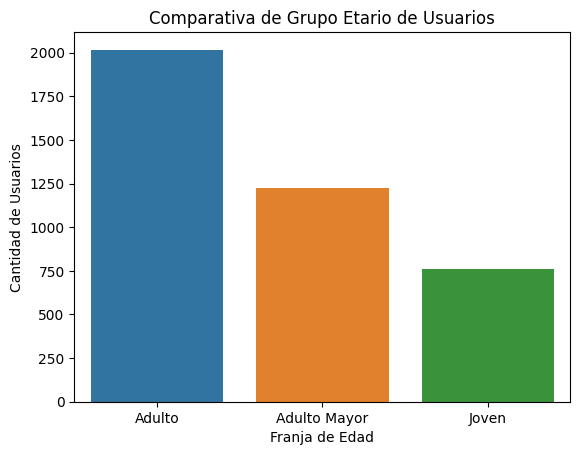

In [50]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.ylabel("Cantidad de Usuarios")
plt.xlabel("Franja de Edad")
plt.title("Comparativa de Grupo Etario de Usuarios")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
 - Outliers y Sentinels: Se identificó un sentil de -999 en la columna age que afectaba el promedio, el cual fue corregido imputando la mediana. En la columna city, se detectó un 11.75% de valores nulos y un 2.4% de "?", las cuales se estandarizaron como valores faltantes para evitar sesgos.

 - Inconsistencias temporales: En reg_date, aparecieron registros futuros, como el año 2026, los cuales se convirtieron a nulos ya que el estudio contempla datos hasta 2024. Adicionalmente, se confirmó que los nulos en duration y length en la tabla de uso responden a un patrón Missing At Random dependiente del tipo de servicio (type: llamada o texto).

🔍 **Segmentos por Edad**
 - La base de usuarios se distribuyó en tres grupos etarios clave: Jóvenes (menores de 30), Adultos(menores de 60) y Adultos Mayores(mayores de 60).
 - Se observa que la distribución de edad no está sesgada de forma extrema y muestra una gran participación del segmento adulto y adulto mayor, destacando que los clientes mayores de 70 años muestran un fuerte interés y afinidad por contratar el plan Premium.


📊 **Segmentos por Nivel de Uso**
 - A partir del cruce de llamadas y mensajes, se clasificó a los usuarios en Bajo uso, Uso medio y Alto uso.

 - Se evidenció una clara predominancia de los usuarios con plan Premium en los niveles de consumo más elevados (tanto en volumen de mensajes como en llamadas y minutos totales), lo que valida que los beneficios del plan se alinean con la actividad real del cliente.

➡️ Esto sugiere que los clientes de mayor valor (plan Premium) son aquellos que exprimen los límites de llamadas y mensajes, y existe una oportunidad clara de retener o migrar a los usuarios de "Uso medio" demostrando el valor agregado de los planes superiores.


💡 **Recomendaciones**
 - Diseñar campañas de marketing dirigidas a los usuarios del plan Básico con un uso medio o alto, ofreciéndoles incentivos de migración al plan Premium mediante paquetes combinados de minutos y datos.
 - Aunque los valores extremos en duración de llamadas (hasta 155 minutos) e interacciones altas no deben eliminarse automáticamente por ser técnicamente posibles, se recomienda establecer alertas de consumo para prevenir posibles fraudes, abusos de red o errores de facturación.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`